# 🏭 Predictive Business Digital Twin Framework
### Capstone Project — Live Demo

This notebook demonstrates the complete pipeline:
1. **Data Generation & Cleaning** — 2 years of synthetic retail data
2. **Feature Engineering** — Calendar, lag, rolling-window features
3. **ML Forecasting** — XGBoost / Random Forest demand prediction
4. **EDA Visualizations** — 5 exploratory plots
5. **Digital Twin Simulation** — 3 inventory policy scenarios
6. **KPI Comparison** — Revenue, profit, service level, stockouts
7. **Validation** — 9 integrity checks across 3 scenarios (27 total checks)

---

## Setup — Import All Modules

In [13]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

from config import *
from data_generation import generate_historical_data, clean_data
from feature_engineering import engineer_features
from forecasting import train_forecast_model, generate_future_demand
from simulation import build_digital_twin, build_demand_lookup, run_simulation, scenario2_transfer_policy
from kpi import build_kpi_table, determine_best_policy
from visualization import *
from validation import validate_all_scenarios

print('✅ All modules imported successfully.')
print(f'   XGBoost available: {XGBOOST_AVAILABLE}')
print(f'   Plotly available:  {PLOTLY_AVAILABLE}')

✅ All modules imported successfully.
   XGBoost available: True
   Plotly available:  True


---
## Part 1 — Generate Historical Dataset
We simulate **2 years** of daily data for **2 warehouses × 3 products** (4,380 records).  
Demand includes weekly/monthly seasonality, upward trend, random promotions, and noise.

In [14]:
raw_df = generate_historical_data()
print(f'Dataset shape: {raw_df.shape}')
print(f'Date range: {raw_df["Date"].min().date()} to {raw_df["Date"].max().date()}')
print(f'Warehouses: {raw_df["Warehouse"].unique().tolist()}')
print(f'Products: {raw_df["Product"].unique().tolist()}')
raw_df.head(10)

Dataset shape: (4380, 13)
Date range: 2024-01-01 to 2025-12-30
Warehouses: ['Warehouse_A', 'Warehouse_B']
Products: ['Product_1', 'Product_2', 'Product_3']


,Date,Warehouse,Product,Demand,Inventory,Selling_Price,Purchase_Cost,Holding_Cost,Shipping_Cost,Supplier,Lead_Time,Order_Quantity,Revenue
0,2024-01-01,Warehouse_A,Product_1,71,429,25.0,14.0,8.58,106.5,Supplier_X,3,0,1775.0
1,2024-01-02,Warehouse_A,Product_1,100,329,25.0,14.0,6.58,150.0,Supplier_X,3,0,2500.0
2,2024-01-03,Warehouse_A,Product_1,86,243,25.0,14.0,4.86,129.0,Supplier_X,3,0,2150.0
3,2024-01-04,Warehouse_A,Product_1,84,159,25.0,14.0,3.18,126.0,Supplier_X,3,0,2100.0
4,2024-01-05,Warehouse_A,Product_1,64,495,25.0,14.0,9.90,96.0,Supplier_X,3,400,1600.0
5,2024-01-06,Warehouse_A,Product_1,62,433,25.0,14.0,8.66,93.0,Supplier_X,3,0,1550.0
6,2024-01-07,Warehouse_A,Product_1,68,365,25.0,14.0,7.30,102.0,Supplier_X,3,0,1700.0
7,2024-01-08,Warehouse_A,Product_1,72,293,25.0,14.0,5.86,108.0,Supplier_X,3,0,1800.0
8,2024-01-09,Warehouse_A,Product_1,86,207,25.0,14.0,4.14,129.0,Supplier_X,3,0,2150.0
9,2024-01-10,Warehouse_A,Product_1,96,511,25.0,14.0,10.22,144.0,Supplier_X,3,400,2400.0


## Part 2 — Data Cleaning
Inject 0.5% missing values → impute with group median (Warehouse × Product).

In [15]:
df = clean_data(raw_df)

Injected 22 missing Demand values for demonstration.
Missing values before cleaning:
Demand    22
dtype: int64
All missing values imputed. Dataset is clean.


## Part 3 — Feature Engineering
Build **12 features**: DayOfWeek, Month, WeekOfYear, IsWeekend, DayIndex, Lag(1/7/14), RollingMean(7/28), WarehouseCode, ProductCode.

In [16]:
df, warehouse_categories, product_categories = engineer_features(df)
df.head()

Feature engineering complete. New columns added:
['DayOfWeek', 'Month', 'WeekOfYear', 'IsWeekend', 'DayIndex', 'Demand_Lag_1', 'Demand_Lag_7', 'Demand_Lag_14', 'Demand_RollMean_7', 'Demand_RollMean_28', 'WarehouseCode', 'ProductCode']


,Date,Warehouse,Product,Demand,Inventory,Selling_Price,Purchase_Cost,Holding_Cost,Shipping_Cost,Supplier,Lead_Time,Order_Quantity,Revenue,DayOfWeek,Month,WeekOfYear,IsWeekend,DayIndex,Demand_Lag_1,Demand_Lag_7,Demand_Lag_14,Demand_RollMean_7,Demand_RollMean_28,WarehouseCode,ProductCode
0,2024-01-01,Warehouse_A,Product_1,71,429,25.0,14.0,8.58,106.5,Supplier_X,3,0,1775.0,0,1,1,0,0,NaN,NaN,NaN,NaN,NaN,0,0
1,2024-01-02,Warehouse_A,Product_1,100,329,25.0,14.0,6.58,150.0,Supplier_X,3,0,2500.0,1,1,1,0,1,71.0,NaN,NaN,NaN,NaN,0,0
2,2024-01-03,Warehouse_A,Product_1,86,243,25.0,14.0,4.86,129.0,Supplier_X,3,0,2150.0,2,1,1,0,2,100.0,NaN,NaN,NaN,NaN,0,0
3,2024-01-04,Warehouse_A,Product_1,84,159,25.0,14.0,3.18,126.0,Supplier_X,3,0,2100.0,3,1,1,0,3,86.0,NaN,NaN,NaN,NaN,0,0
4,2024-01-05,Warehouse_A,Product_1,64,495,25.0,14.0,9.90,96.0,Supplier_X,3,400,1600.0,4,1,1,0,4,84.0,NaN,NaN,NaN,NaN,0,0


---
## Part 4 — Exploratory Data Analysis (EDA)
### 4.1 — Demand Trend by Warehouse

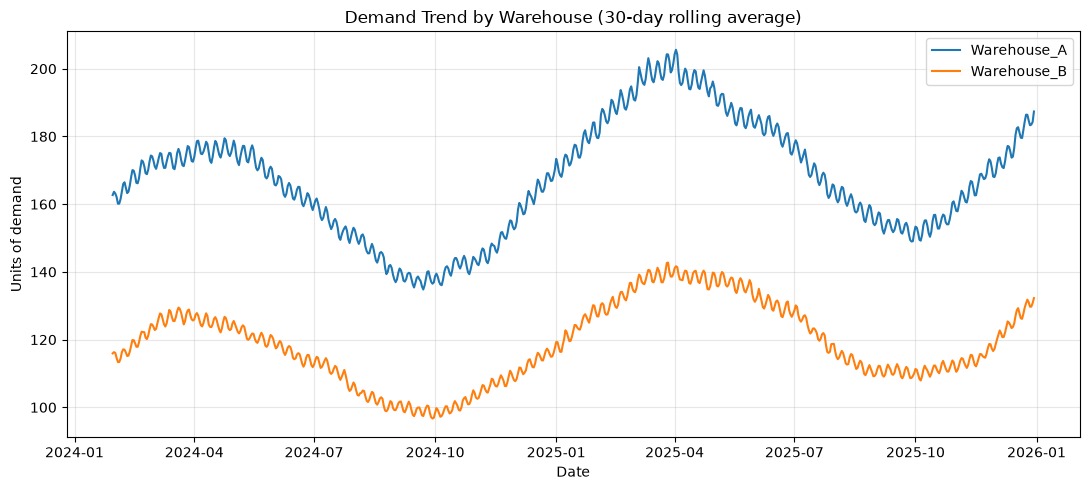

Interpretation: both warehouses show clear upward trend and seasonal cycles, with Warehouse_A consistently demanding more units than Warehouse_B, consistent with its higher base-demand multiplier.


In [17]:
plot_demand_trend(df)

### 4.2 — Historical Inventory Over Time

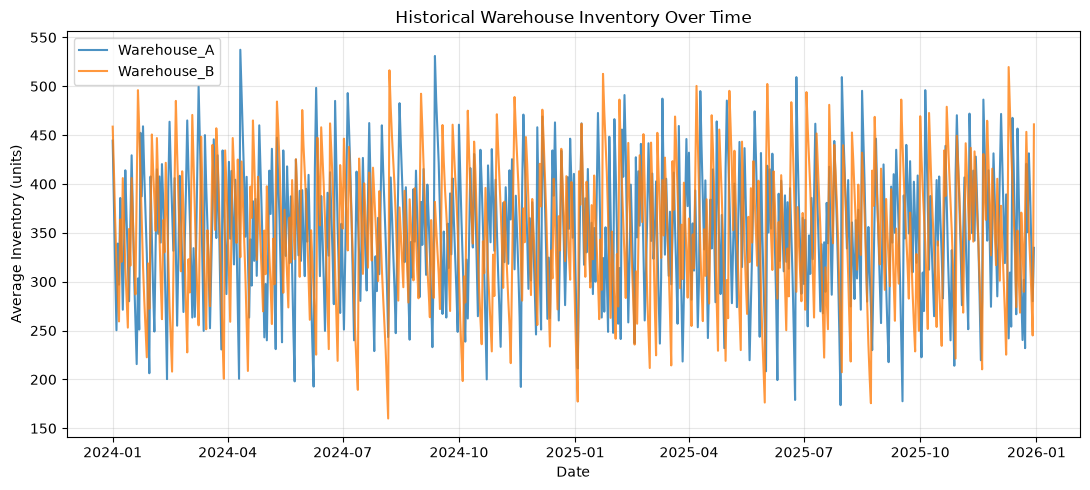

Interpretation: the sawtooth pattern reflects the historical reorder-point policy — inventory depletes with sales and jumps back up whenever a replenishment order arrives.


In [18]:
plot_inventory_history(df)

### 4.3 — Revenue Trend

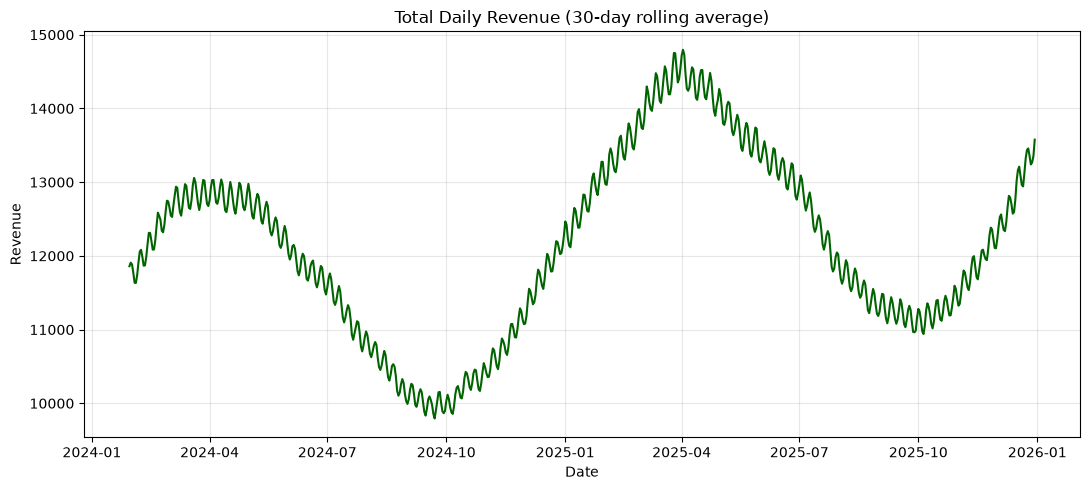

Interpretation: revenue tracks the demand trend closely, confirming that pricing was held constant historically and revenue is primarily volume-driven.


In [19]:
plot_revenue_trend(df)

### 4.4 — Monthly Demand Seasonality

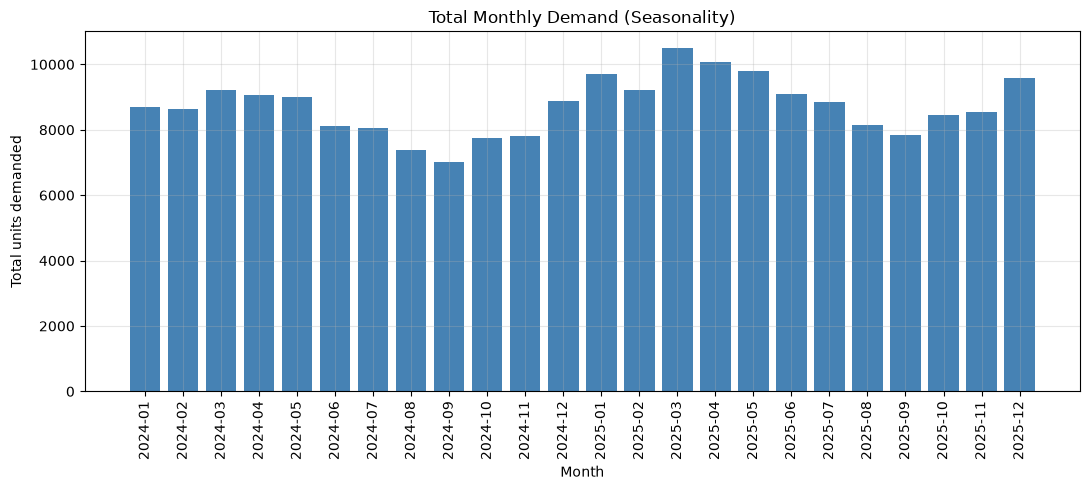

Interpretation: monthly totals reveal a mild seasonal cycle superimposed on a gradual upward trend across the two-year history — exactly the pattern a forecasting model needs to learn.


In [20]:
plot_monthly_demand(df)

### 4.5 — Correlation Heatmap

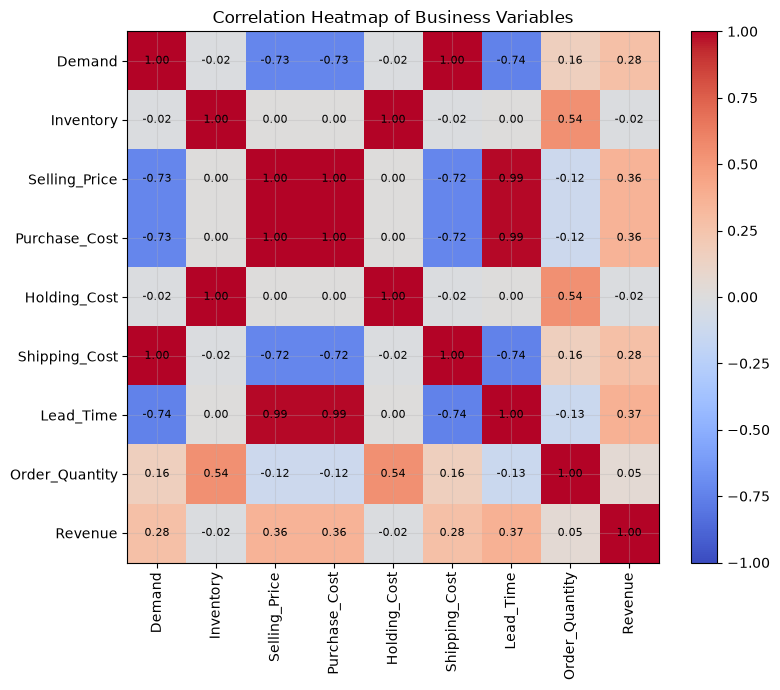

Interpretation: Demand and Revenue are strongly positively correlated (revenue is volume-driven). Order_Quantity is weakly related to same-day demand because reordering is triggered by inventory depletion, not by the current day's demand.


In [21]:
plot_correlation_heatmap(df)

---
## Part 5 — Train Demand Forecasting Model
**XGBoost** (or Random Forest fallback) with 80/20 chronological train-test split.

In [22]:
forecast_model, test_df, mae, rmse, r2 = train_forecast_model(df)

Training rows: 3369  |  Test rows: 843
Train period: 2024-01-29 to 2025-08-12
Test period:  2025-08-12 to 2025-12-30

Demand Forecasting Model Performance (hold-out test set):
  MAE  = 4.28 units
  RMSE = 6.48 units
  R^2  = 0.906


### Actual vs Predicted Demand

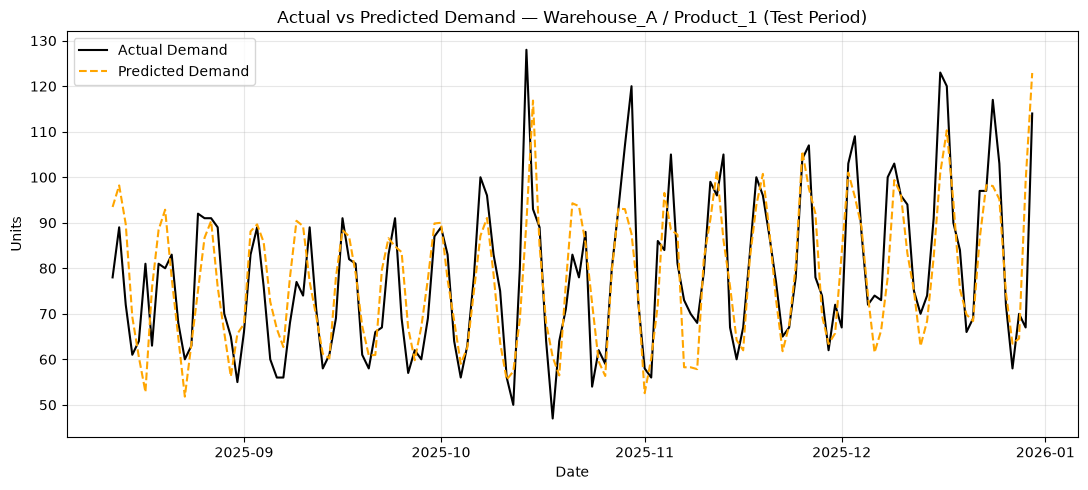

Interpretation: predicted demand tracks the seasonal and weekly pattern of actual demand closely, confirming the model has learned the underlying demand structure well enough to drive downstream inventory-decision simulation.


In [23]:
plot_actual_vs_predicted(test_df)

---
## Part 6 — Generate 60-Day Future Demand Forecast
Recursive multi-step prediction for each warehouse/product combination.

In [24]:
predicted_demand_df, future_dates = generate_future_demand(df, forecast_model)
predicted_demand_df.head(10)

Generated 360 predicted-demand rows covering 60 future days for all Warehouse/Product combinations.


,Date,Warehouse,Product,Predicted_Demand
0,2025-12-31,Warehouse_A,Product_1,125
1,2026-01-01,Warehouse_A,Product_1,104
2,2026-01-02,Warehouse_A,Product_1,81
3,2026-01-03,Warehouse_A,Product_1,70
4,2026-01-04,Warehouse_A,Product_1,75
5,2026-01-05,Warehouse_A,Product_1,85
6,2026-01-06,Warehouse_A,Product_1,110
7,2026-01-07,Warehouse_A,Product_1,130
8,2026-01-08,Warehouse_A,Product_1,121
9,2026-01-09,Warehouse_A,Product_1,80


---
## Part 7 — Digital Twin Simulation
### Object-Oriented Architecture
```
Supplier → Warehouse → Inventory → BusinessDigitalTwin
                                    ↕ Transportation
```

### Three Scenarios:
| # | Scenario | Description |
|---|----------|-------------|
| S1 | Current Policy | Baseline reorder-point (trigger=400, qty=700) |
| S2 | Transfer Policy | Proactive A→B transfers with 7-day lookahead |
| S3 | Increased Reorder | 1.5× reorder quantity for larger safety stock |

In [25]:
demand_lookup = build_demand_lookup(predicted_demand_df)

# Scenario 1 — Current Inventory Policy
print('Running Scenario 1 (Current Inventory Policy)...')
twin_s1 = build_digital_twin()
twin_s1 = run_simulation(twin_s1, demand_lookup, SIMULATION_HORIZON_DAYS,
                          future_dates, reorder_multiplier=1.0, transfer_policy=None)
twin_s1.display_state()

Running Scenario 1 (Current Inventory Policy)...
BUSINESS DIGITAL TWIN — CURRENT STATE
--- Warehouse_A ---  (Supplier: Supplier_of_Warehouse_A, Lead Time: 5d)
   Product_1: 44 / 1500 units (2.9% utilized), pending orders: 700
   Product_2: 496 / 1500 units (33.1% utilized), pending orders: 0
   Product_3: 631 / 1500 units (42.1% utilized), pending orders: 0
--- Warehouse_B ---  (Supplier: Supplier_of_Warehouse_B, Lead Time: 7d)
   Product_1: 0 / 1500 units (0.0% utilized), pending orders: 700
   Product_2: 233 / 1500 units (15.5% utilized), pending orders: 700
   Product_3: 728 / 1500 units (48.5% utilized), pending orders: 0
------------------------------------------------------------
Cumulative Revenue:      954,375.00
Cumulative Profit:       328,755.04
Cumulative Stockouts:    798 units
Service Level:           96.46%


In [26]:
# Scenario 2 — Inventory Transfer Policy
print('Running Scenario 2 (Inventory Transfer Policy)...')
twin_s2 = build_digital_twin()
twin_s2 = run_simulation(twin_s2, demand_lookup, SIMULATION_HORIZON_DAYS,
                          future_dates, reorder_multiplier=1.0,
                          transfer_policy=scenario2_transfer_policy)
print(f'Transfers executed: {len(twin_s2.transfer_log)}')
twin_s2.display_state()

Running Scenario 2 (Inventory Transfer Policy)...
Transfers executed: 30
BUSINESS DIGITAL TWIN — CURRENT STATE
--- Warehouse_A ---  (Supplier: Supplier_of_Warehouse_A, Lead Time: 5d)
   Product_1: 176 / 1500 units (11.7% utilized), pending orders: 700
   Product_2: 608 / 1500 units (40.5% utilized), pending orders: 0
   Product_3: 628 / 1500 units (41.9% utilized), pending orders: 0
--- Warehouse_B ---  (Supplier: Supplier_of_Warehouse_B, Lead Time: 7d)
   Product_1: 644 / 1500 units (42.9% utilized), pending orders: 0
   Product_2: 121 / 1500 units (8.1% utilized), pending orders: 700
   Product_3: 731 / 1500 units (48.7% utilized), pending orders: 0
------------------------------------------------------------
Cumulative Revenue:      969,975.00
Cumulative Profit:       332,189.58
Cumulative Stockouts:    174 units
Service Level:           99.23%


In [27]:
# Scenario 3 — Increased Reorder Quantity
print('Running Scenario 3 (Increased Reorder Quantity)...')
twin_s3 = build_digital_twin()
twin_s3 = run_simulation(twin_s3, demand_lookup, SIMULATION_HORIZON_DAYS,
                          future_dates, reorder_multiplier=1.5, transfer_policy=None)
twin_s3.display_state()

Running Scenario 3 (Increased Reorder Quantity)...
BUSINESS DIGITAL TWIN — CURRENT STATE
--- Warehouse_A ---  (Supplier: Supplier_of_Warehouse_A, Lead Time: 5d)
   Product_1: 466 / 1500 units (31.1% utilized), pending orders: 0
   Product_2: 496 / 1500 units (33.1% utilized), pending orders: 0
   Product_3: 981 / 1500 units (65.4% utilized), pending orders: 0
--- Warehouse_B ---  (Supplier: Supplier_of_Warehouse_B, Lead Time: 7d)
   Product_1: 530 / 1500 units (35.3% utilized), pending orders: 0
   Product_2: 583 / 1500 units (38.9% utilized), pending orders: 0
   Product_3: 728 / 1500 units (48.5% utilized), pending orders: 0
------------------------------------------------------------
Cumulative Revenue:      956,825.00
Cumulative Profit:       326,714.92
Cumulative Stockouts:    700 units
Service Level:           96.90%


---
## Part 8 — KPI Comparison

In [28]:
scenario_twins = {
    'Scenario 1\n(Current Policy)': twin_s1,
    'Scenario 2\n(Transfer Policy)': twin_s2,
    'Scenario 3\n(Increased Reorder Qty)': twin_s3,
}

kpi_table = build_kpi_table(scenario_twins)
kpi_table.round(2)

,Revenue,Purchase_Cost,Holding_Cost,Shipping_Cost,Transfer_Cost,Profit,Ending_Inventory,Avg_Inventory,Warehouse_Utilization_%,Stockout_Units,Service_Level_%,Order_Fill_Rate_%,Inventory_Turnover
Scenario,,,,,,,,,,,,,
Scenario 1\n(Current Policy),954375.0,590100.0,2867.96,32652.0,0.0,328755.04,2132,398.33,26.56,798,96.46,96.46,54.65
Scenario 2\n(Transfer Policy),969975.0,599900.0,2917.42,33588.0,1380.0,332189.58,2908,405.20,27.01,174,99.23,99.23,55.26
Scenario 3\n(Increased Reorder Qty),956825.0,593250.0,4061.08,32799.0,0.0,326714.92,3784,564.04,37.60,700,96.90,96.90,38.77


### Best Policy Determination

In [29]:
recommended, reason = determine_best_policy(kpi_table)

BEST POLICY DETERMINATION
                                        Profit  Service_Level_%  \
Scenario                                                          
Scenario 1\n(Current Policy)         328755.04        96.463706   
Scenario 2\n(Transfer Policy)        332189.58        99.228928   
Scenario 3\n(Increased Reorder Qty)  326714.92        96.897988   

                                     Stockout_Units  Warehouse_Utilization_%  
Scenario                                                                      
Scenario 1\n(Current Policy)                    798                26.555185  
Scenario 2\n(Transfer Policy)                   174                27.013148  
Scenario 3\n(Increased Reorder Qty)             700                37.602593  
------------------------------------------------------------
Highest profit:        Scenario 2
(Transfer Policy)  (Profit = 332,189.58)
Highest service level: Scenario 2
(Transfer Policy)  (Service Level = 99.23%)
RECOMMENDED POLICY: Scenario 

---
## Part 9 — Scenario Comparison Charts

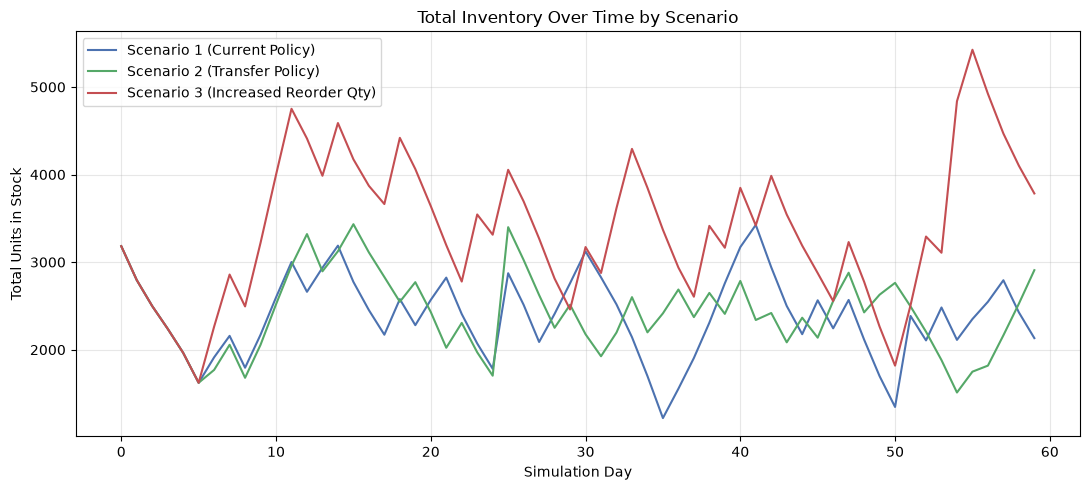

In [30]:
plot_scenario_inventory(scenario_twins)

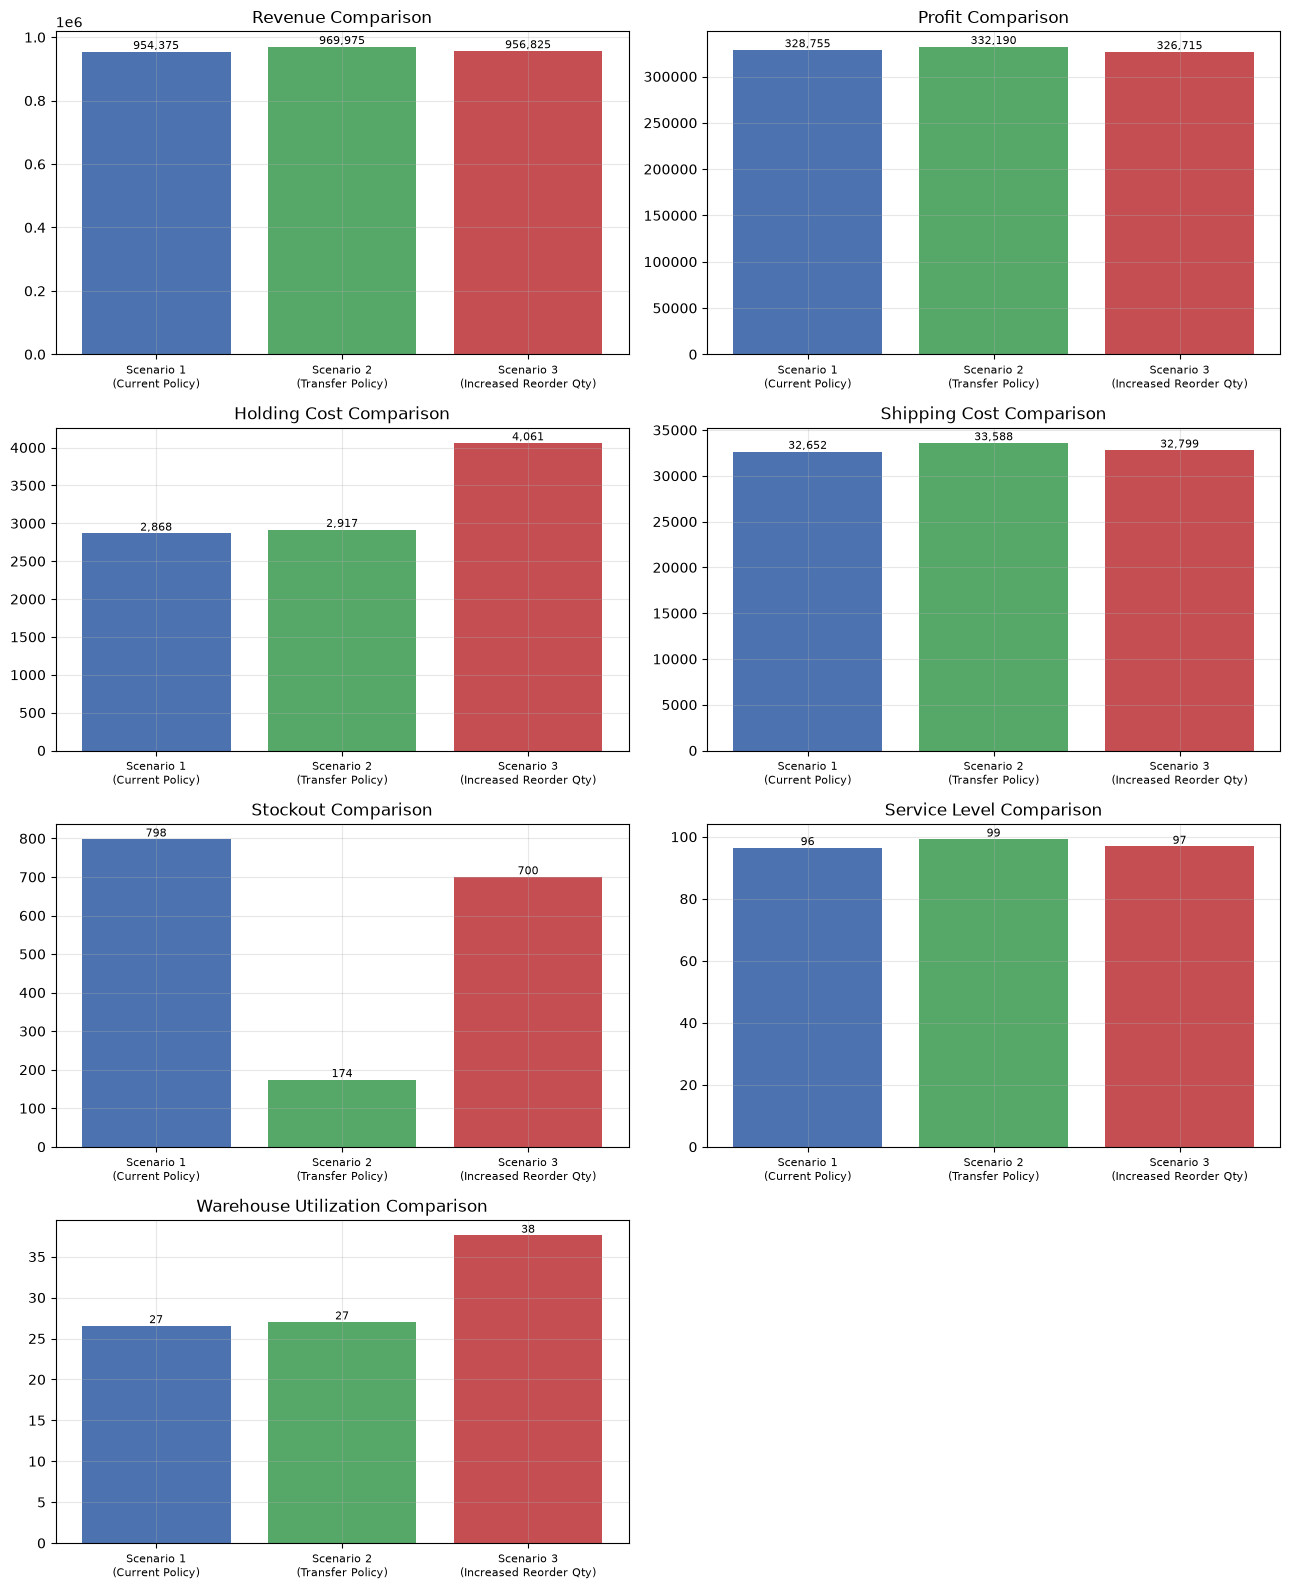

In [31]:
plot_kpi_bars(kpi_table)

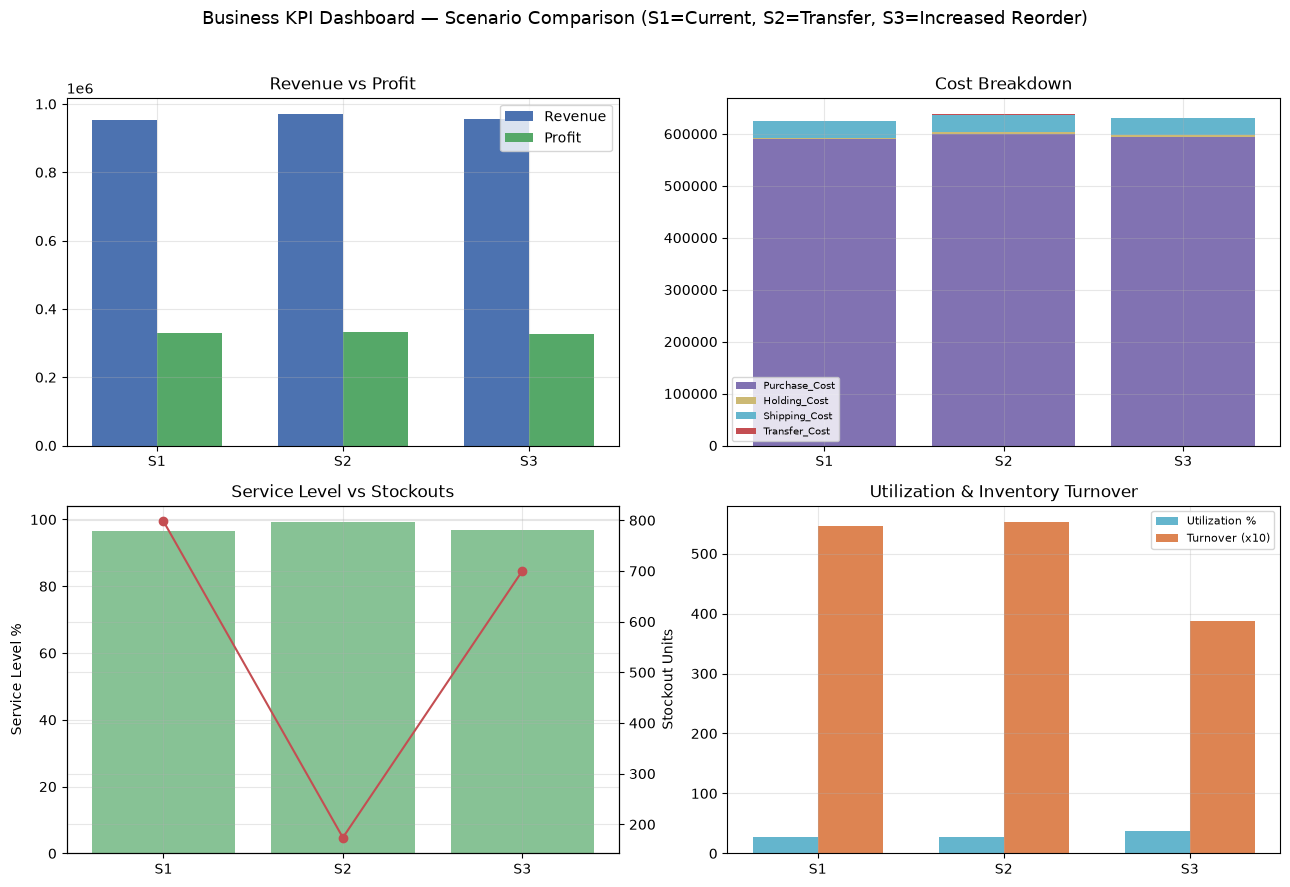

In [32]:
plot_kpi_dashboard(kpi_table)

---
## Part 10 — Validation (9 Integrity Checks × 3 Scenarios = 27 Total Checks)

In [33]:
validate_all_scenarios(scenario_twins, kpi_table)

Validation results for Scenario 1 (Current Policy):
  [PASS] Inventory never negative
  [PASS] Inventory never exceeds capacity
  [PASS] Revenue = Units Sold x Selling Price
  [PASS] Purchase cost is non-negative
  [PASS] Purchase cost > 0 only when orders were placed
  [PASS] Shipping cost proportional to units sold
  [PASS] Holding cost proportional to remaining inventory
  [PASS] Stockouts within [0, Demand] bounds
  [PASS] Profit = Revenue - Purchase - Holding - Shipping - Transfer

Validation results for Scenario 2 (Transfer Policy):
  [PASS] Inventory never negative
  [PASS] Inventory never exceeds capacity
  [PASS] Revenue = Units Sold x Selling Price
  [PASS] Purchase cost is non-negative
  [PASS] Purchase cost > 0 only when orders were placed
  [PASS] Shipping cost proportional to units sold
  [PASS] Holding cost proportional to remaining inventory
  [PASS] Stockouts within [0, Demand] bounds
  [PASS] Profit = Revenue - Purchase - Holding - Shipping - Transfer

Validation resu

True

---
## Part 11 — Conclusion

In [34]:
print('=' * 60)
print('RESEARCH CONCLUSION')
print('=' * 60)
model_name = 'XGBoost' if XGBOOST_AVAILABLE else 'Random Forest (fallback)'
print(f'The demand forecasting model ({model_name}) achieved:')
print(f'  MAE  = {mae:.2f} units')
print(f'  RMSE = {rmse:.2f} units')
print(f'  R²   = {r2:.3f}')
print()
print('An R² above 0.85 indicates the model explains the large majority of demand')
print('variance, capturing weekly and monthly seasonality, trend, and product/warehouse')
print('effects well enough to be a credible input for downstream inventory simulation.')
print()
print(f'RECOMMENDED POLICY: {recommended}')
print(f'Reason: {reason}.')
print('=' * 60)
print('✅ Pipeline complete.')

RESEARCH CONCLUSION
The demand forecasting model (XGBoost) achieved:
  MAE  = 4.28 units
  RMSE = 6.48 units
  R²   = 0.906

An R² above 0.85 indicates the model explains the large majority of demand
variance, capturing weekly and monthly seasonality, trend, and product/warehouse
effects well enough to be a credible input for downstream inventory simulation.

RECOMMENDED POLICY: Scenario 2
(Transfer Policy)
Reason: it simultaneously maximizes profit and customer service level.
✅ Pipeline complete.
